# House Price Prediction ML Project

#### Life cycle of Machine learning Project

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model

### **1. Problem Statement**

`Business Problem`

The real estate industry requires accurate property valuation to help buyers, sellers, banks, and real estate agencies make informed decisions. Manually estimating house prices is time-consuming and may lead to inconsistent results because house prices depend on multiple factors such as area, number of bedrooms, bathrooms, location, age of the property, condition, and garage availability.

The objective of this project is to build a machine learning model that predicts the selling price of a house based on its characteristics. The developed model will assist in estimating house prices quickly and accurately.

`Objective`

Develop a regression model that predicts the house price (price) using the available house features.

### **2. Data Collection**
- Dataset Source - https://www.kaggle.com/datasets/zafarali27/house-price-prediction-dataset
- The data consists of 10 column and 2,000 rows.

**2.1 Import Libraries**

In [49]:
# data handling
# model saving 

# visualization
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

# regression models
from sklearn.linear_model import LinearRegression

# Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

**2.3 Import CSV dataset**

In [5]:
df = pd.read_csv('House Price Prediction Dataset.csv')

**2.4 understand your data**

In [6]:
df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [26]:
df.tail()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


**Shape of datatset**

In [7]:
df.shape

(2000, 10)

In [27]:
df.columns

Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price'],
      dtype='str')

**2.5 Dataset Information**

`Input Features`
* Area
* Bedrooms
* Bathrooms
* Floors
* YearBuilt
* Location
* Condition
* Garage

`Target Feature`
* Price

### **3. Data Checks to perform**

- Check Missing values
- Check Duplicates
- Check data type
- Check the number of unique values of each column
- Check statistics of data set
- Check various categories present in the different categorical column

**3.1 Check Missing values**

In [8]:
df.isna().sum()

Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

There are no missing values in the data set

**3.2  Check Duplicates**

In [9]:
df.duplicated().sum()

np.int64(0)

There are no duplicates  values in the data set

**3.3 Check data type**

In [10]:
# Check Null and Dtypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 184.3 KB


**3.4 Check the number of unique values of each column**

In [11]:
df.nunique()

Id           2000
Area         1622
Bedrooms        5
Bathrooms       4
Floors          3
YearBuilt     124
Location        4
Condition       4
Garage          2
Price        1999
dtype: int64

**3.5 Check statistics of data set**

In [12]:
df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


#### Insight
- From above description of numerical data, all means are very close to each other - between 66 and 68.05;
- All standard deviations are also close - between 14.6 and 15.19;
- While there is a minimum score  0 for math, for writing minimum is much higher = 10 and for reading myet higher = 17

**3.6 Check various categories present in the different categorical column**

### **4. Exploring Data ( Visualization )**

**4.1 Visualize average sale distribution to make some conclusion.** 
- Histogram
- Countplot
- Boxplot

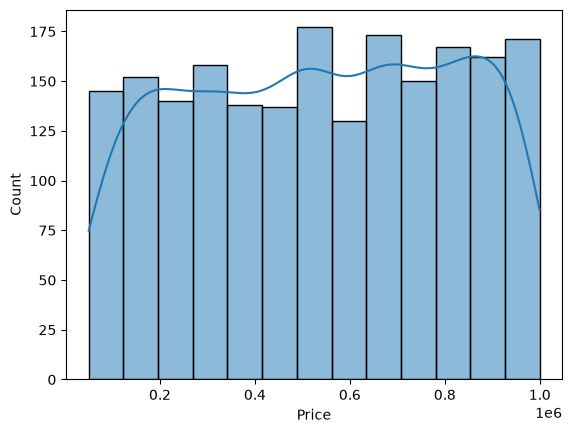

In [13]:
sns.histplot(df["Price"], kde=True)
plt.show()

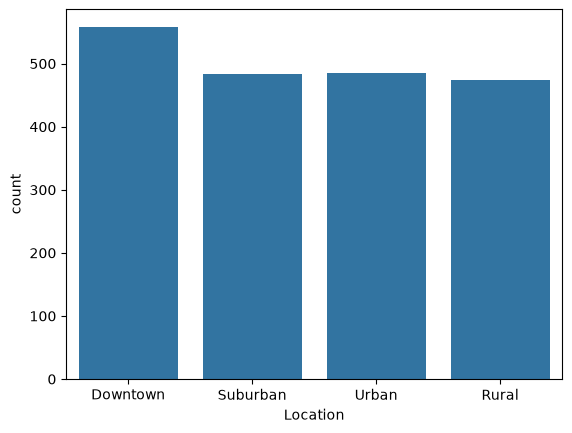

In [14]:
sns.countplot(x="Location", data=df)
plt.show()

**4.2 Bivariate Analysis**
Relationship between two variables.

Examples:
- Area vs Price
- Bedrooms vs Price
- Bathrooms vs Price
- Garage vs Price

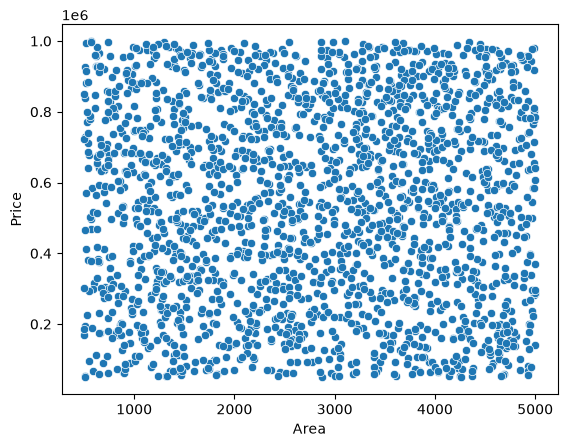

In [25]:
sns.scatterplot(x="Area", y="Price", data=df)
plt.show()

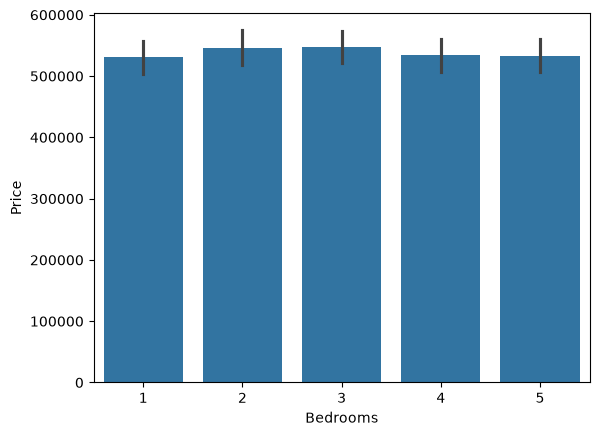

In [23]:
sns.barplot(x="Bedrooms", y="Price", data=df)
plt.show()

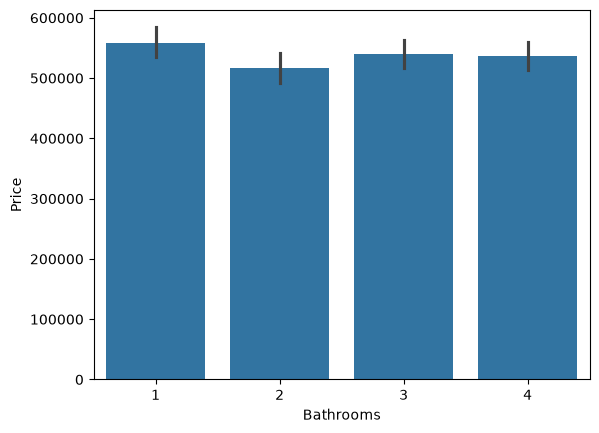

In [21]:
sns.barplot(x="Bathrooms", y="Price", data=df)
plt.show()

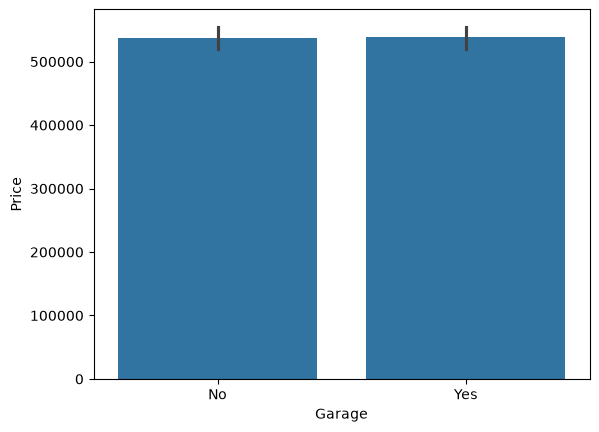

In [20]:
sns.barplot(x="Garage", y="Price", data=df)
plt.show()

**4.3 Multivariate Analysis**

<Axes: >

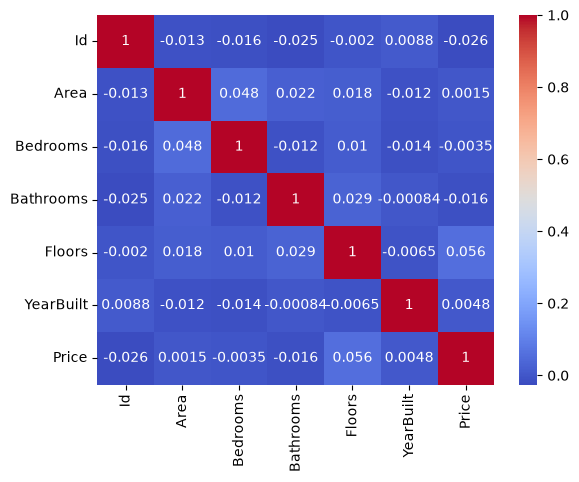

In [16]:
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

**4.4 Outlier detection**

In [29]:
df.columns

Index(['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price'],
      dtype='str')

<Axes: >

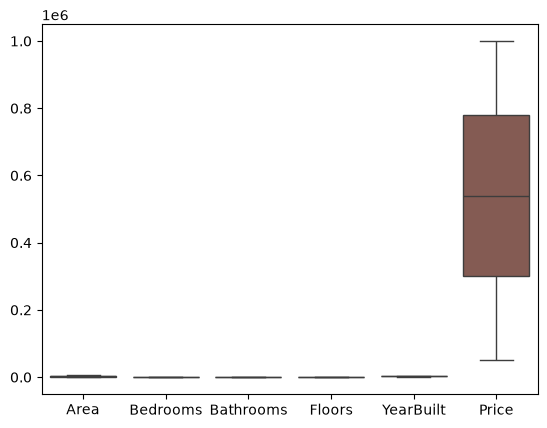

In [31]:
sns.boxplot(df[['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt',
       'Location', 'Condition', 'Garage', 'Price']])

### **5. Data Preprocessing**

**5.1 Drop Unnecessary Columns**

In [32]:
df.drop("Id", axis=1, inplace=True)

**5.2 Handle Missing Values**

There is not missing values in dataset

**5.3 Feature Engineering**

In [33]:
import datetime

current_year = datetime.datetime.today().year
df["HouseAge"] = current_year - df["YearBuilt"]

Drop:

In [34]:
df.drop("YearBuilt", axis=1, inplace=True)

**5.4 Train-Test Split**

In [35]:
X = df.drop("Price", axis=1)

y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

preprocessing pipeline:

In [36]:
df.dtypes

Area         int64
Bedrooms     int64
Bathrooms    int64
Floors       int64
Location       str
Condition      str
Garage         str
Price        int64
HouseAge     int64
dtype: object

In [39]:
# feature categories
num_cols = ['Area', 'Bedrooms','Bathrooms','Floors','HouseAge']
cat_cols = ['Location', 'Condition','Garage']

# Create the preprocessor pipeline
num_transformer = Pipeline([
    ('scaler',StandardScaler())
])

cat_transformer = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


preprocessor = ColumnTransformer([
    ('num_processing', num_transformer, num_cols),
    ('cat_processing',cat_transformer, cat_cols)
])

X_train_array = preprocessor.fit_transform(X_train)
X_test_array = preprocessor.transform(X_test)

#Extract the correct processed column names from the preprocessor
feature_names = preprocessor.get_feature_names_out()

#Convert arrays back into Pandas DataFrames
X_train_advanced = pd.DataFrame(
    X_train_array, columns=feature_names, index=X_train.index
)
X_test_advanced = pd.DataFrame(
    X_test_array, columns=feature_names, index=X_test.index
)

### **6. Model Training**

In [43]:
lr = LinearRegression()
lr.fit(X_train_advanced, y_train)

dt = DecisionTreeRegressor(max_depth=10, min_samples_split=5)
dt.fit(X_train_advanced, y_train)

rf = RandomForestRegressor(
    n_estimators=200, max_depth=15, min_samples_split=5
)
rf.fit(X_train_advanced, y_train)

gb = GradientBoostingRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=5
)
gb.fit(X_train_advanced, y_train)

xgb_model = XGBRegressor(
    n_estimators=300, learning_rate=0.05, max_depth=6
)
xgb_model.fit(X_train_advanced, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


**Evaluation**

In [52]:
models = {
    "Linear Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "Gradient Boosting": gb,
    "XGBoost": xgb_model,
}

for name, model in models.items():
    predictions = model.predict(X_test_advanced)
    
    # Calculate MSE normally
    mse = mean_squared_error(y_test, predictions)
    # Take the square root manually to get RMSE
    rmse = np.sqrt(mse) 
    
    print(f"--- {name} Performance ---")
    print(f"R2 Score (Accuracy): {r2_score(y_test, predictions)*100}")
    print(f"Mean Absolute Error: {mean_absolute_error(y_test, predictions):.2f}")
    print(f"Mean Squared Error: {mse:.2f}")
    print(f"Root Mean Squared Error: {rmse:.2f}\n")


--- Linear Regression Performance ---
R2 Score (Accuracy): -0.6717808430749761
Mean Absolute Error: 243241.98
Mean Squared Error: 78321466146.03
Root Mean Squared Error: 279859.73

--- Decision Tree Performance ---
R2 Score (Accuracy): -35.94242330108912
Mean Absolute Error: 272098.49
Mean Squared Error: 105761612789.81
Root Mean Squared Error: 325210.11

--- Random Forest Performance ---
R2 Score (Accuracy): -8.72584797975502
Mean Absolute Error: 251942.99
Mean Squared Error: 84587436026.58
Root Mean Squared Error: 290839.19

--- Gradient Boosting Performance ---
R2 Score (Accuracy): -13.19358891402793
Mean Absolute Error: 254933.86
Mean Squared Error: 88063286134.74
Root Mean Squared Error: 296754.59

--- XGBoost Performance ---
R2 Score (Accuracy): -14.796805381774902
Mean Absolute Error: 253737.38
Mean Squared Error: 89310560256.00
Root Mean Squared Error: 298848.72



### **7. Hyperparameter Tuning**

Use: `GridSearchCV` or `RandomizedSearchCV`

Tune parameters such as:
* n_estimators
* max_depth
* min_samples_split
* learning_rate

**Model Comparison**

Create a comparison table.

Select the model with the lowest RMSE/MAE and highest R² score.

### **6. Model Building**

- Understanding the Problem Statement
- Data Collection
- Data Checks to perform
- Exploratory data analysis
- Data Pre-Processing
- Model Training
- Choose best model